# Fase 0 · Explorando los datos de SPHEREx

Objetivo: dadas unas coordenadas, (1) preguntar a IRSA qué observaciones las cubren, (2) bajar un *cutout* y (3) entender qué hay dentro de cada archivo FITS.

Resumen de lo que vas a encontrar:

- Cada observación es un archivo **MEF** (multi-extension FITS) de ~70 MB por detector y exposición. El cutout devuelve las mismas extensiones pero recortadas.
- Extensiones: `IMAGE`, `FLAGS`, `VARIANCE`, `ZODI`, `PSF`, `WCS-WAVE`.
- Cada **píxel** tiene su propia longitud de onda (el filtro es de variación lineal), así que una imagen NO es una sola banda: la longitud de onda cambia a lo largo de la imagen.
- Los 6 detectores (`SPHEREx-D1` … `SPHEREx-D6`) cubren distintos rangos de longitud de onda.

Fuentes: [Data Access](https://caltech-ipac.github.io/spherex-archive-documentation/spherex-data-access/), [Data Products](https://caltech-ipac.github.io/spherex-archive-documentation/spherex-data-products/) y el tutorial [Spectral Image cutouts](https://caltech-ipac.github.io/irsa-tutorials/spherex-cutouts/).

In [2]:
# !pip install numpy astropy astroquery matplotlib
import time
import logging
import concurrent.futures

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.time import Time
from astropy.wcs import WCS
from astropy.visualization import ZScaleInterval
from astroquery.ipac.irsa import Irsa
from astropy.utils.data import conf

logging.getLogger("astropy").setLevel(logging.ERROR)  # evita avisos repetidos de WCS alternos
conf.remote_timeout = 120                             # los archivos SPHEREx pueden tardar en leerse

## 1. Objetivo y tamaño del recorte

WISE 0855 viene con las coordenadas del enunciado. Los otros tres se resuelven por nombre con SIMBAD (necesita internet).

Dato útil para más adelante: WISE 0855 tiene un movimiento propio muy grande (del orden de 8″ por año), mientras que un píxel de SPHEREx mide ~6.2″. Es decir, en un año se mueve poco más de un píxel: el efecto es sutil y por eso hace falta alinear bien las imágenes.

In [3]:
# Respaldo por si SIMBAD/Sesame no responde (timeouts de red).
# eps Ind A y RW Aur: coordenadas J2000/ICRS tomadas de Wikipedia.
# eps Ind B y R Dra: NO las tengo verificadas. Si Sesame falla, busca "eps Ind B" y "R Dra" en
# https://simbad.cds.unistra.fr/simbad/ y descomenta/pega aquí sus coordenadas.
FALLBACK = {
    "eps Ind A": SkyCoord("22h03m21.65363s", "-56d47m09.5228s", frame="icrs"),
    "RW Aur": SkyCoord("05h07m49.4562s", "+30d24m04.774s", frame="icrs"),
    # "eps Ind B": SkyCoord("hh mm ss.s", "+dd mm ss.s", frame="icrs"),
    # "R Dra": SkyCoord("hh mm ss.s", "+dd mm ss.s", frame="icrs"),
}


def resolve(name, retries=1):
    for _ in range(retries + 1):
        try:
            return SkyCoord.from_name(name)
        except Exception as e:
            err = e
            time.sleep(2)
    print(f"[{name}] Sesame no respondió ({type(err).__name__}); uso respaldo si existe.")
    return FALLBACK.get(name)


TARGETS = {
    "WISE 0855": SkyCoord("08h55m10.831s", "-07d14m42.53s", frame="icrs"),
}
for name in ["eps Ind A", "eps Ind B", "RW Aur", "R Dra"]:
    c = resolve(name)
    if c is None:
        print(f"[{name}] sin coordenadas: pégalas a mano en FALLBACK.")
    else:
        TARGETS[name] = c

for k, v in TARGETS.items():
    print(f"{k:10s} RA={v.ra.deg:.5f}  Dec={v.dec.deg:+.5f}")

TARGET = "WISE 0855"       # cambia aquí para probar los otros
coord = TARGETS[TARGET]
SIZE = 0.1 * u.deg         # lado del recorte

[eps Ind A] Sesame no respondió (NameResolveError); uso respaldo si existe.
[eps Ind B] Sesame no respondió (NameResolveError); uso respaldo si existe.
[eps Ind B] sin coordenadas: pégalas a mano en FALLBACK.
[RW Aur] Sesame no respondió (NameResolveError); uso respaldo si existe.
[R Dra] Sesame no respondió (NameResolveError); uso respaldo si existe.
[R Dra] sin coordenadas: pégalas a mano en FALLBACK.
WISE 0855  RA=133.79513  Dec=-7.24515
eps Ind A  RA=330.84022  Dec=-56.78598
RW Aur     RA=76.95607  Dec=+30.40133


## 2. ¿Qué observaciones cubren este punto? (TAP)

Se usa el servicio TAP de IRSA. La tabla `spherex.plane` tiene el polígono de cada observación (`poly`), su detector (`energy_bandpassname`) y su fecha (`time_bounds_lower`); `spherex.artifact` tiene la URL del archivo. A la URL se le añade `?center=RA,Dec&size=...` y IRSA devuelve el cutout.

La consulta puede tardar unos 15 segundos.

In [4]:
def query_observations(coord, size=SIZE, bandpass=None):
    cond = f"AND p.energy_bandpassname = '{bandpass}'" if bandpass else ""
    query = f"""
    SELECT
        'https://irsa.ipac.caltech.edu/' || a.uri || '?center={coord.ra.deg},{coord.dec.deg}d&size={size.value}' AS uri,
        p.time_bounds_lower,
        p.energy_bandpassname
    FROM spherex.artifact a
    JOIN spherex.plane p ON a.planeid = p.planeid
    WHERE 1 = CONTAINS(POINT('ICRS', {coord.ra.deg}, {coord.dec.deg}), p.poly)
    {cond}
    ORDER BY p.time_bounds_lower
    """
    return Irsa.query_tap(query).to_table()


t0 = time.time()
obs = query_observations(coord)
print(f"{len(obs)} observaciones en {time.time() - t0:.1f} s")
obs[:5]

256 observaciones en 14.1 s


uri,time_bounds_lower,energy_bandpassname
,d,
object,float64,object
"https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W19_1B/l2b-v20-2025-241/3/level2_2025W19_1B_0116_1D3_spx_l2b-v20-2025-241.fits?center=133.79512916666664,-7.245147222222222d&size=0.1",60800.700028,SPHEREx-D3
"https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W19_1B/l2b-v20-2025-241/6/level2_2025W19_1B_0116_1D6_spx_l2b-v20-2025-241.fits?center=133.79512916666664,-7.245147222222222d&size=0.1",60800.700028,SPHEREx-D6
"https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W19_1B/l2b-v20-2025-241/6/level2_2025W19_1B_0116_2D6_spx_l2b-v20-2025-241.fits?center=133.79512916666664,-7.245147222222222d&size=0.1",60800.701521,SPHEREx-D6
"https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W19_1B/l2b-v20-2025-241/3/level2_2025W19_1B_0116_2D3_spx_l2b-v20-2025-241.fits?center=133.79512916666664,-7.245147222222222d&size=0.1",60800.701521,SPHEREx-D3
"https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W19_1B/l2b-v20-2025-241/6/level2_2025W19_1B_0138_1D6_spx_l2b-v20-2025-241.fits?center=133.79512916666664,-7.245147222222222d&size=0.1",60800.834438,SPHEREx-D6


In [5]:
# Resumen: cuántas observaciones por detector y qué rango de fechas
# (time_bounds_lower está en MJD; los años impresos deberían ser 2025-2026)
obs["date"] = Time(np.array(obs["time_bounds_lower"], dtype=float), format="mjd").iso
for det in np.unique(obs["energy_bandpassname"]):
    sel = obs[obs["energy_bandpassname"] == det]
    print(f"{det}: {len(sel):3d} obs   {sel['date'][0][:10]} -> {sel['date'][-1][:10]}")

n_dates = len(np.unique([d[:10] for d in obs["date"]]))
print(f"\nFechas distintas: {n_dates}")

SPHEREx-D1:  36 obs   2025-05-06 -> 2026-05-05
SPHEREx-D2:  48 obs   2025-05-06 -> 2026-05-14
SPHEREx-D3:  45 obs   2025-05-05 -> 2026-05-11
SPHEREx-D4:  36 obs   2025-05-06 -> 2026-05-05
SPHEREx-D5:  48 obs   2025-05-06 -> 2026-05-14
SPHEREx-D6:  43 obs   2025-05-05 -> 2026-05-11

Fechas distintas: 27


**Qué mirar aquí:** si hay muy pocas fechas distintas, el “video” será corto. Guarda este número para cada uno de los 4 objetivos; define qué tan bien se verá el movimiento.

## 3. Bajar un cutout y ver su estructura

Se toma la primera observación del detector D2 (cualquier otra sirve).

In [6]:
row = obs[obs["energy_bandpassname"] == "SPHEREx-D2"][0]
url = row["uri"]
print(url)

hdul = fits.open(url)   # descarga el recorte (queda en caché de astropy)
hdul.info()

https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W19_1B/l2b-v20-2025-241/2/level2_2025W19_1B_0181_1D2_spx_l2b-v20-2025-241.fits?center=133.79512916666664,-7.245147222222222d&size=0.1
Filename: C:\Users\thena\.astropy\cache\download\url\71a658810ba23e2476d07a9617f4b476\contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       239   (59, 59)   float32   
  2  FLAGS         1 ImageHDU       146   (59, 59)   int32   
  3  VARIANCE      1 ImageHDU       119   (59, 59)   float32   
  4  ZODI          1 ImageHDU       119   (59, 59)   float32   
  5  PSF           1 ImageHDU       509   (101, 101, 121)   float32   
  6  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [11J, 11J, 242E]   


In [7]:
# Header primario: metadatos generales de la observación (sin datos de imagen)
for k, v in list(hdul[0].header.items())[:45]:
    print(f"{k:10s} = {v}")

SIMPLE     = True
BITPIX     = 8
NAXIS      = 0
EXTEND     = True
VERSION    = 6.4+psffix1


In [8]:
# Header de IMAGE: unidades y WCS espacial
hdr = hdul["IMAGE"].header
for key in ["EXTNAME", "NAXIS1", "NAXIS2", "BUNIT", "CTYPE1", "CTYPE2",
            "CRVAL1", "CRVAL2", "CRPIX1", "CRPIX2", "CD1_1", "CD1_2", "CD2_1", "CD2_2"]:
    print(f"{key:8s} = {hdr.get(key)}")
print("\nTamaño de cada extensión:")
for h in hdul:
    print(f"  {h.name:9s} {h.data.shape if h.data is not None else None}")

EXTNAME  = IMAGE
NAXIS1   = 59
NAXIS2   = 59
BUNIT    = MJy / sr
CTYPE1   = RA---TAN-SIP
CTYPE2   = DEC--TAN-SIP
CRVAL1   = 133.937383538
CRVAL2   = -8.38185405112
CRPIX1   = 320.5
CRPIX2   = 635.5
CD1_1    = None
CD1_2    = None
CD2_1    = None
CD2_2    = None

Tamaño de cada extensión:
  PRIMARY   None
  IMAGE     (59, 59)
  FLAGS     (59, 59)
  VARIANCE  (59, 59)
  ZODI      (59, 59)
  PSF       (121, 101, 101)
  WCS-WAVE  (1,)


**Anota:** la unidad (`BUNIT`, debería ser MJy/sr), el tamaño en píxeles del recorte y la extensión `PSF`, que NO es una imagen del cielo (su WCS es de ángulos del detector, no RA/Dec).

## 4. Las capas: IMAGE, VARIANCE, ZODI y FLAGS

Se marca con una cruz la posición del objetivo usando el WCS del propio recorte.

Objetivo en el píxel (x=29.3, y=29.0)


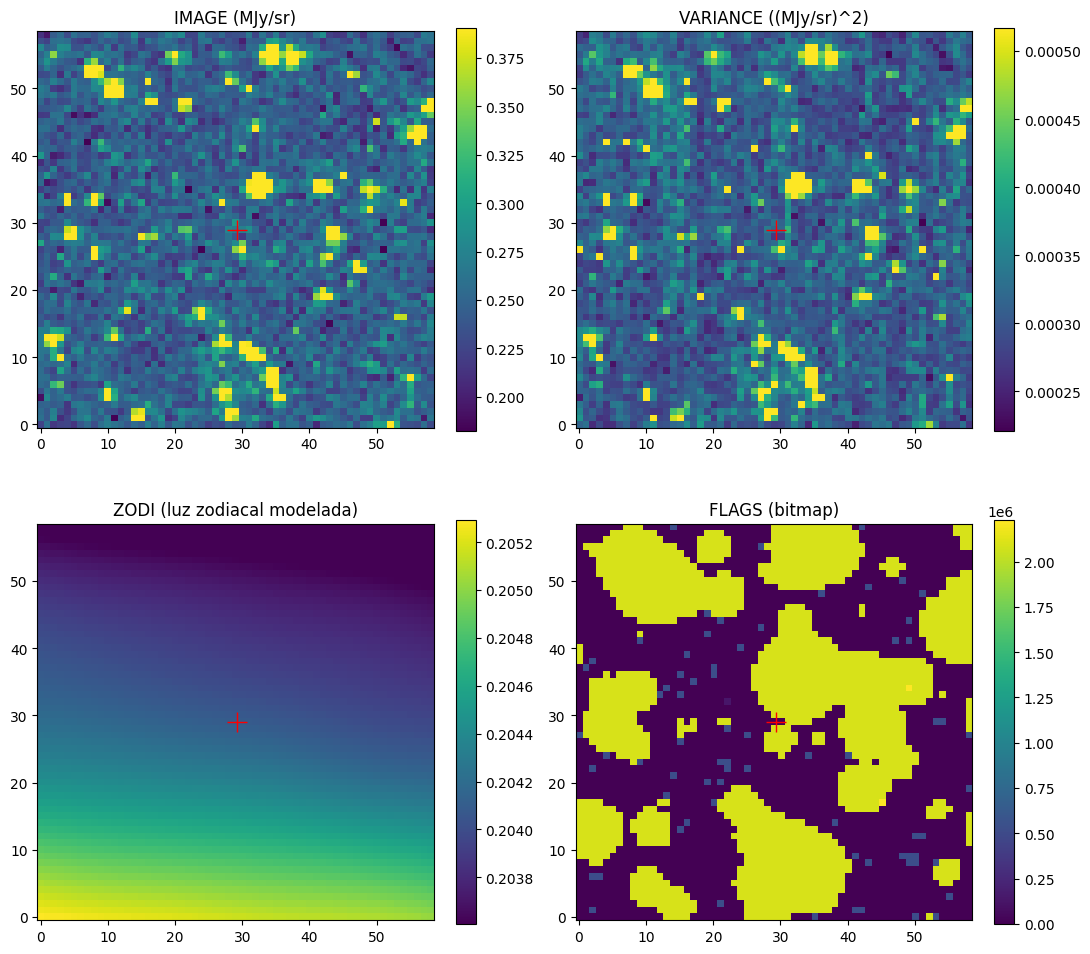

In [9]:
spatial_wcs = WCS(hdul["IMAGE"].header)
x0, y0 = spatial_wcs.world_to_pixel(coord)
print(f"Objetivo en el píxel (x={x0:.1f}, y={y0:.1f})")


def show(ax, data, title, log=False):
    d = np.array(data, dtype=float)
    ok = np.isfinite(d)
    vmin, vmax = ZScaleInterval().get_limits(d[ok]) if ok.any() else (0, 1)
    im = ax.imshow(d, origin="lower", vmin=vmin, vmax=vmax, cmap="viridis")
    ax.plot(x0, y0, "r+", ms=14)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)


fig, axs = plt.subplots(2, 2, figsize=(11, 10))
show(axs[0, 0], hdul["IMAGE"].data, "IMAGE (MJy/sr)")
show(axs[0, 1], hdul["VARIANCE"].data, "VARIANCE ((MJy/sr)^2)")
show(axs[1, 0], hdul["ZODI"].data, "ZODI (luz zodiacal modelada)")
show(axs[1, 1], hdul["FLAGS"].data, "FLAGS (bitmap)")
plt.tight_layout()
plt.show()

**Nota sobre `ZODI`:** es un modelo del fondo de luz zodiacal que viene como referencia y **no está restado** de `IMAGE`. Si quieres ver el objeto sin fondo, esa es una decisión de procesamiento tuya (restar el modelo, o restar una mediana, etc.).

In [10]:
# FLAGS es un bitmap: cada bit significa algo (saturación, rayo cósmico, fuente enmascarada, etc.).
# Aquí solo vemos qué bits aparecen y en qué fracción de píxeles.
flags = np.asarray(hdul["FLAGS"].data).astype(np.int64)
print("bits activos:")
for b in range(32):
    frac = np.mean((flags & (1 << b)) > 0)
    if frac > 0:
        print(f"  bit {b:2d}: {100 * frac:6.2f}% de los píxeles")

bits activos:
  bit  0:   0.43% de los píxeles
  bit  2:   0.26% de los píxeles
  bit  6:   0.06% de los píxeles
  bit 11:   0.03% de los píxeles
  bit 17:   0.09% de los píxeles
  bit 19:   2.04% de los píxeles
  bit 21:  41.51% de los píxeles


**Pendiente (importante):** el significado exacto de cada bit está en el [Explanatory Supplement](https://irsa.ipac.caltech.edu/data/SPHEREx/docs/SPHEREx_Expsupp_QR.pdf). Cópialo a una tabla en tu código: sirve para la capa de “máscara de contaminación” de la web.

## 5. Longitud de onda por píxel

Esta es la parte más rara de SPHEREx: el filtro varía a lo largo del detector, así que cada píxel tiene su propia longitud de onda y ancho de banda. El WCS espectral está en `WCS-WAVE` y se lee con `key="W"`.

Aviso de la documentación: `WCS-WAVE` es una aproximación pensada para visualización (~1 nm); para ciencia se recomienda el producto aparte *Spectral WCS* (extensiones `CWAVE` y `CBAND`, un archivo de ~32 MB por detector).

Longitud de onda en el objetivo: 1.5164 um
Rango de longitud de onda en el recorte: 1.5072 - 1.5260 um


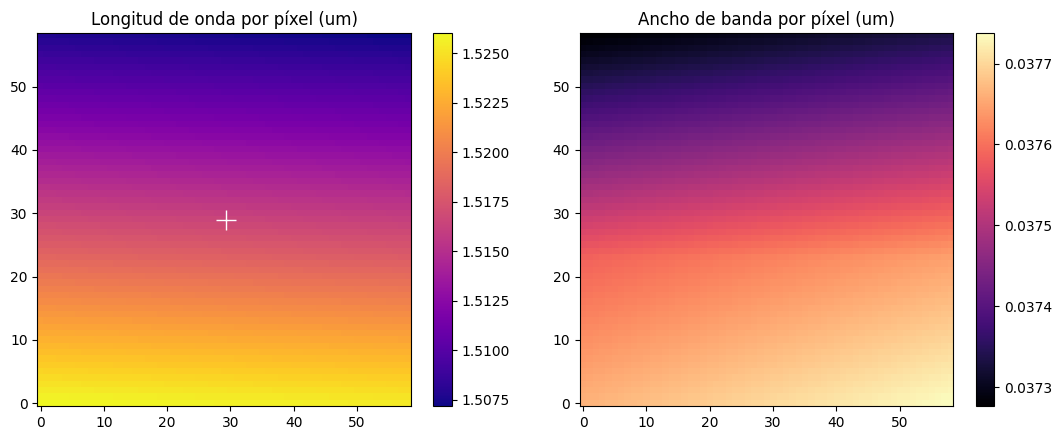

In [11]:
ny, nx = hdul["IMAGE"].data.shape
spec_wcs = WCS(hdul["IMAGE"].header, fobj=hdul, key="W")
spec_wcs.sip = None

yy, xx = np.mgrid[0:ny, 0:nx]
wave, bandwidth = spec_wcs.pixel_to_world(xx, yy)
wave_um = wave.to(u.micrometer).value
bw_um = bandwidth.to(u.micrometer).value

wl_target = wave_um[int(round(float(y0))), int(round(float(x0)))]
print(f"Longitud de onda en el objetivo: {wl_target:.4f} um")
print(f"Rango de longitud de onda en el recorte: {wave_um.min():.4f} - {wave_um.max():.4f} um")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
im = axs[0].imshow(wave_um, origin="lower", cmap="plasma")
axs[0].plot(x0, y0, "w+", ms=14)
axs[0].set_title("Longitud de onda por píxel (um)")
plt.colorbar(im, ax=axs[0], fraction=0.046)
im = axs[1].imshow(bw_um, origin="lower", cmap="magma")
axs[1].set_title("Ancho de banda por píxel (um)")
plt.colorbar(im, ax=axs[1], fraction=0.046)
plt.tight_layout()
plt.show()

**Qué significa para el proyecto:** en cada exposición, el objetivo cae en UNA longitud de onda concreta. Para tener las 102 bandas hay que juntar exposiciones distintas. Ahí está la idea del “espectro instantáneo”: es el flujo del objetivo en cada exposición, graficado contra la longitud de onda de ese píxel.

## 6. Un vistazo a los 6 detectores

Para cada detector se toma su primera observación y se calcula qué longitud de onda ve el objetivo.

In [12]:
def inspect_obs(row, coord):
    """Devuelve fecha, longitud de onda y flujo (mediana 3x3) en el objetivo para un cutout."""
    with fits.open(row["uri"]) as h:
        wcs_s = WCS(h["IMAGE"].header)
        x, y = wcs_s.world_to_pixel(coord)
        wcs_w = WCS(h["IMAGE"].header, fobj=h, key="W")
        wcs_w.sip = None
        wl, _ = wcs_w.pixel_to_world(x, y)
        img = np.array(h["IMAGE"].data, dtype=float)
        xi, yi = int(round(float(x))), int(round(float(y)))
        patch = img[max(yi - 1, 0):yi + 2, max(xi - 1, 0):xi + 2]
        return {
            "det": row["energy_bandpassname"],
            "date": row["date"][:10],
            "wave_um": float(wl.to(u.micrometer).value),
            "flux_MJy_sr": float(np.nanmedian(patch)),
        }


first_per_det = [obs[obs["energy_bandpassname"] == d][0] for d in np.unique(obs["energy_bandpassname"])]
for r in first_per_det:
    try:
        print(inspect_obs(r, coord))
    except Exception as e:
        print(r["energy_bandpassname"], "falló:", e)

{'det': 'SPHEREx-D1', 'date': '2025-05-06', 'wave_um': 0.9936670117647599, 'flux_MJy_sr': 0.2442951798439026}
{'det': 'SPHEREx-D2', 'date': '2025-05-06', 'wave_um': 1.5164510397189326, 'flux_MJy_sr': 0.2616124451160431}
{'det': 'SPHEREx-D3', 'date': '2025-05-05', 'wave_um': 2.3649521291878974, 'flux_MJy_sr': 0.16849955916404724}
{'det': 'SPHEREx-D4', 'date': '2025-05-06', 'wave_um': 3.36181453250498, 'flux_MJy_sr': 0.15139012038707733}
{'det': 'SPHEREx-D5', 'date': '2025-05-06', 'wave_um': 4.2899602914231085, 'flux_MJy_sr': 0.38348525762557983}
{'det': 'SPHEREx-D6', 'date': '2025-05-05', 'wave_um': 4.962048267031303, 'flux_MJy_sr': 0.8127576112747192}


## 7. Varias épocas: el germen del espectro y del video

Se procesan las primeras observaciones en paralelo. IRSA recomienda no pasarse de ~10 hilos. Si alguna descarga falla, es normal (errores transitorios): la función la salta.

24 de 24 cutouts leídos


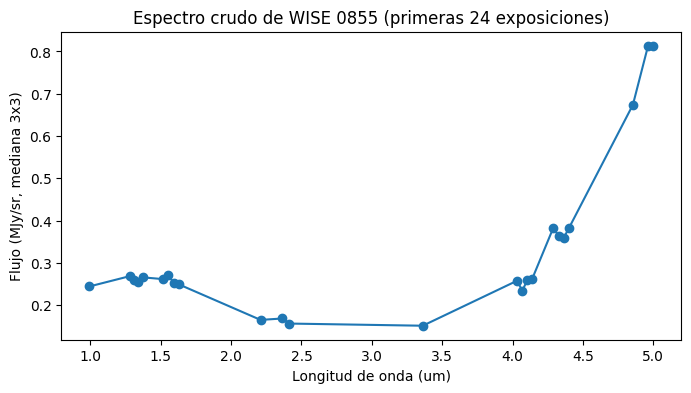

In [13]:
def safe_inspect(row):
    try:
        return inspect_obs(row, coord)
    except Exception:
        return None


subset = obs[:24]
with concurrent.futures.ThreadPoolExecutor(max_workers=8) as ex:
    results = [r for r in ex.map(safe_inspect, subset) if r is not None]

print(f"{len(results)} de {len(subset)} cutouts leídos")
results.sort(key=lambda r: r["wave_um"])

waves = [r["wave_um"] for r in results]
flux = [r["flux_MJy_sr"] for r in results]
plt.figure(figsize=(8, 4))
plt.plot(waves, flux, "o-")
plt.xlabel("Longitud de onda (um)")
plt.ylabel("Flujo (MJy/sr, mediana 3x3)")
plt.title(f"Espectro crudo de {TARGET} (primeras {len(results)} exposiciones)")
plt.show()

## Qué anotar al terminar la Fase 0

Rellena esto para cada uno de los 4 objetivos:

| Objetivo | Nº de observaciones | Nº de fechas distintas | Detectores que lo cubren | Rango de fechas |
|---|---|---|---|---|
| WISE 0855 |256 | 27| 	D1 a D6 (los seis)|2025-05-05 → 2026-05-14 |
| eps Ind B | | | | |
| RW Aur | | | | |
| R Dra | | | | |

Preguntas abiertas para la Fase 1:

1. ¿Cuántas fechas distintas hay? (define qué tan largo y útil será el video)
2. ¿El flujo del objetivo se ve por encima del ruido en `VARIANCE`?
3. ¿Qué bits de `FLAGS` caen sobre el objetivo?
4. ¿Cómo comparas dos imágenes de distinta longitud de onda? (si el brillo cambia con la banda, restarlas no basta)
5. ¿Qué versión de procesamiento tiene cada archivo (`VERSION` en el header primario)? Lo necesitas para la actualización a la versión final.


1.- 27 fechas para 256 observaciones, unas 9 o 10 exposiciones por fecha. Pero el número importante es otro: cada detector tiene entre 36 y 48 observaciones y, según un artículo de mapeo de SPHEREx, cada detector se divide en 17 canales espectrales. Eso da solo 2 o 3 observaciones por banda (inferencia mía, no un dato impreso). Un video de una sola banda tendría 2 o 3 cuadros. Para llegar a 27 fechas hay que mezclar bandas, y eso complica las restas (ver pregunta 4).

2.-
La varianza ronda 0.00025 a 0.0005 (MJy/sr)², es decir, un ruido de ~0.016 a 0.022 MJy/sr por píxel.
El flujo en el objetivo es 0.262 y el modelo ZODI vale ~0.204, así que el exceso es ~0.057 MJy/sr (unas 3σ por píxel).
Pero ese exceso parece un nivel de fondo de toda la imagen (el fondo ronda 0.23 a 0.27 en todo el recorte), no una fuente puntual. En el panel de IMAGE no se ve nada especial en la cruz.

3.-
El bit 21 domina: afecta al 41.5 % de los píxeles. Coincide con el máximo de la barra de color (~2.1×10⁶ ≈ 2²¹).
Las manchas amarillas de FLAGS cubren las fuentes brillantes de IMAGE, lo que sugiere una máscara de fuentes (la documentación menciona que se crea una). Confírmalo en el Explanatory Supplement.
Al ampliar el panel, la cruz parece caer en un píxel sin máscara, pegado a regiones enmascaradas. Con un píxel de margen, hay que verificarlo con código (abajo).

4.-
No se pueden restar directamente. Tus datos lo muestran: el flujo en el objetivo va de 0.15 a 0.81 MJy/sr según el detector (D1: 0.24, D2: 0.26, D3: 0.17, D4: 0.15, D5: 0.38, D6: 0.81). Restar bandas distintas dejaría un residuo enorme que no es movimiento. Dentro de un cutout la longitud de onda casi no cambia (1.5072 a 1.5260 µm), así que cada recorte equivale a prácticamente una banda. La regla de trabajo:

Restar solo exposiciones del mismo detector y con longitud de onda en el objetivo parecida (una tolerancia basada en el ancho de banda).
Alinear las imágenes primero (el objetivo cae en píxeles distintos en cada exposición) y restar ZODI o una mediana de referencia.

5.-
Del único archivo que revisaste (D2, semana 2025W19): VERSION = 6.4+psffix1, y la ruta dice l2b-v20-2025-241. Los de 2026 probablemente vienen de otro release, pues los ejemplos del tutorial de IRSA mezclan v20 y v25, pero no lo has comprobado para WISE 0855.



In [15]:
# Si reiniciaste el kernel y no existe hdul, se vuelve a descargar el cutout de D2
if "hdul" not in globals():
    row = obs[obs["energy_bandpassname"] == "SPHEREx-D2"][0]
    hdul = fits.open(row["uri"])

# Posición del objetivo en el recorte (float, para evitar el error de round)
spatial_wcs = WCS(hdul["IMAGE"].header)
x0, y0 = spatial_wcs.world_to_pixel(coord)
x0, y0 = float(x0), float(y0)
xi, yi = int(round(x0)), int(round(y0))

img  = np.array(hdul["IMAGE"].data,    dtype=float)
var  = np.array(hdul["VARIANCE"].data, dtype=float)
zodi = np.array(hdul["ZODI"].data,     dtype=float)
flg  = np.array(hdul["FLAGS"].data).astype(np.int64)
ny, nx = img.shape

if not (0 <= xi < nx and 0 <= yi < ny):
    raise ValueError(f"El objetivo cae fuera del recorte: x={x0:.1f}, y={y0:.1f}, tamaño={nx}x{ny}")
print(f"Objetivo en el píxel x={x0:.1f}, y={y0:.1f}")

# Vecindario 3x3 alrededor del objetivo
ys, xs = slice(max(yi - 1, 0), yi + 2), slice(max(xi - 1, 0), xi + 2)
p_img, p_var, p_zodi, p_flg = img[ys, xs], var[ys, xs], zodi[ys, xs], flg[ys, xs]

# --- Pregunta 2: ¿se ve sobre el ruido? ---
exceso = np.nanmedian(p_img - p_zodi)                   # flujo menos modelo zodiacal
sigma_pix = np.sqrt(np.nanmedian(p_var))                # ruido por píxel (de VARIANCE)
sigma_med = 1.253 * sigma_pix / np.sqrt(p_img.size)     # ruido aproximado de la mediana 3x3
print("\n--- Señal vs. ruido ---")
print(f"Flujo (mediana 3x3):        {np.nanmedian(p_img):.4f} MJy/sr")
print(f"Modelo ZODI (mediana 3x3):  {np.nanmedian(p_zodi):.4f} MJy/sr")
print(f"Exceso IMAGE - ZODI:        {exceso:.4f} MJy/sr")
print(f"Ruido por píxel (VARIANCE): {sigma_pix:.4f} MJy/sr")
print(f"Ruido de la mediana 3x3:    {sigma_med:.4f} MJy/sr  -> exceso = {exceso / sigma_med:.1f} sigma")

# Comparación con el ruido real de la imagen (píxeles sin ninguna máscara)
limpio = (flg == 0) & np.isfinite(img)
if limpio.sum() > 20:
    mad = 1.4826 * np.nanmedian(np.abs(img[limpio] - np.nanmedian(img[limpio])))
    print(f"Nivel de fondo (píxeles sin máscara):  {np.nanmedian(img[limpio]):.4f} MJy/sr")
    print(f"Dispersión real del fondo (MAD):       {mad:.4f} MJy/sr")
    print(f"Fondo menos ZODI:                      {np.nanmedian(img[limpio] - zodi[limpio]):.4f} MJy/sr")
    print("(si el exceso del objetivo es parecido a 'fondo menos ZODI', es fondo y no el objeto)")

# --- Pregunta 3: ¿qué bits de FLAGS caen sobre el objetivo? ---
def bits_de(valor):
    return [b for b in range(32) if int(valor) & (1 << b)]

print("\n--- FLAGS ---")
print(f"Valor en el píxel del objetivo: {flg[yi, xi]}  -> bits {bits_de(flg[yi, xi])}")
bits_3x3 = sorted({b for v in p_flg.ravel() for b in bits_de(v)})
print(f"Bits presentes en el 3x3:       {bits_3x3}")
print(f"Píxeles del 3x3 con alguna máscara: {np.sum(p_flg > 0)} de {p_flg.size}")
for b in bits_3x3:
    n = np.sum((p_flg & (1 << b)) > 0)
    print(f"   bit {b:2d}: {n} de {p_flg.size} píxeles del 3x3")
print("Significado de cada bit: ver el Explanatory Supplement (no lo adivines).")

# Tabla para completar con el significado de cada bit
FLAG_BITS = {b: "?" for b in range(32)}   # <- rellena con la tabla del Explanatory Supplement

Objetivo en el píxel x=29.3, y=29.0

--- Señal vs. ruido ---
Flujo (mediana 3x3):        0.2616 MJy/sr
Modelo ZODI (mediana 3x3):  0.2041 MJy/sr
Exceso IMAGE - ZODI:        0.0575 MJy/sr
Ruido por píxel (VARIANCE): 0.0179 MJy/sr
Ruido de la mediana 3x3:    0.0075 MJy/sr  -> exceso = 7.7 sigma
Nivel de fondo (píxeles sin máscara):  0.2449 MJy/sr
Dispersión real del fondo (MAD):       0.0189 MJy/sr
Fondo menos ZODI:                      0.0406 MJy/sr
(si el exceso del objetivo es parecido a 'fondo menos ZODI', es fondo y no el objeto)

--- FLAGS ---
Valor en el píxel del objetivo: 0  -> bits []
Bits presentes en el 3x3:       [21]
Píxeles del 3x3 con alguna máscara: 4 de 9
   bit 21: 4 de 9 píxeles del 3x3
Significado de cada bit: ver el Explanatory Supplement (no lo adivines).


In [16]:
import re

def release_de(url):
    m = re.search(r"l2b-v(\d+)-(\d{4})-(\d+)", url)
    return m.group(0) if m else "desconocido"

obs["release"] = [release_de(u_) for u_ in obs["uri"]]

print("Releases presentes y cuántas observaciones tiene cada uno:")
vals, cuentas = np.unique(obs["release"], return_counts=True)
for v_, c_ in zip(vals, cuentas):
    sel = obs[obs["release"] == v_]
    print(f"  {v_:22s} {c_:4d} obs   {sel['date'][0][:10]} -> {sel['date'][-1][:10]}")

# Versión interna del header primario del cutout que ya abriste
print("\nVERSION en el header primario del cutout abierto:", hdul[0].header.get("VERSION"))

Releases presentes y cuántas observaciones tiene cada uno:
  l2b-v20-2025-241         26 obs   2025-05-05 -> 2025-05-06
  l2b-v20-2025-242          4 obs   2025-05-06 -> 2025-05-06
  l2b-v20-2025-307         24 obs   2025-10-31 -> 2025-10-31
  l2b-v20-2025-311         12 obs   2025-11-03 -> 2025-11-03
  l2b-v20-2025-314         36 obs   2025-11-07 -> 2025-11-08
  l2b-v20-2025-318         19 obs   2025-11-10 -> 2025-11-10
  l2b-v20-2025-321         17 obs   2025-11-14 -> 2025-11-14
  l2b-v20-2025-349         18 obs   2025-12-11 -> 2025-12-13
  l2b-v24-2026-115         20 obs   2026-04-21 -> 2026-04-23
  l2b-v24-2026-118         10 obs   2026-04-26 -> 2026-04-26
  l2b-v24-2026-125         38 obs   2026-04-30 -> 2026-05-03
  l2b-v24-2026-131         20 obs   2026-05-04 -> 2026-05-09
  l2b-v24-2026-135         12 obs   2026-05-11 -> 2026-05-14

VERSION en el header primario del cutout abierto: 6.4+psffix1


In [ ]:
from astropy.table import Table

def resumen_objetivo(name, c):
    o = query_observations(c)
    if len(o) == 0:
        return {"objetivo": name, "n_obs": 0, "fechas": 0, "detectores": "-",
                "desde": "-", "hasta": "-", "obs_por_det": "-"}
    mjd = np.array(o["time_bounds_lower"], dtype=float)
    iso = Time(mjd, format="mjd").iso
    dets = np.unique(o["energy_bandpassname"])
    por_det = [int(np.sum(o["energy_bandpassname"] == d)) for d in dets]
    return {
        "objetivo": name,
        "n_obs": len(o),
        "fechas": len({s[:10] for s in iso}),
        "detectores": ",".join(d.replace("SPHEREx-", "") for d in dets),
        "desde": iso.min()[:10],
        "hasta": iso.max()[:10],
        "obs_por_det": f"{min(por_det)}-{max(por_det)}",
    }

filas = []
for name, c in TARGETS.items():
    try:
        filas.append(resumen_objetivo(name, c))
        print("listo:", name)
    except Exception as e:
        print(f"{name} falló: {type(e).__name__}: {e}")

tabla = Table(rows=filas)
tabla